In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#matplotlib inline
pd.set_option('display.max_columns', None)

# Part 1: Analyzing Best-Seller Trends Across Product Categories

In [2]:
data = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df = data.copy()

In [3]:
df.shape

(2443651, 9)

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [6]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [7]:
print(df.isnull().sum())
print("\n",df.isna().sum())
print("\n",df.duplicated().sum())

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

 uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

 0


In [8]:
num = df.select_dtypes(include = 'number')
cat = df.select_dtypes(exclude = 'number')

In [9]:
num.shape

(2443651, 5)

In [10]:
cat.shape

(2443651, 4)

In [11]:
#crosstab_cat_isBest = pd.crosstab(cat.category, cat.isBestSeller)
crosstab_cat_isBest = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_cat_isBest

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [12]:
ct_proportion = crosstab_cat_isBest[True] / (crosstab_cat_isBest[True] + crosstab_cat_isBest[False])
best_seller_analysis = ct_proportion.sort_values(ascending=False)
print("Proportion of Best-Sellers by Category:")
print(best_seller_analysis)

Proportion of Best-Sellers by Category:
category
Grocery                             0.058135
Smart Home Security & Lighting      0.057692
Health & Personal Care              0.057686
Mobile Phone Accessories            0.042471
Power & Hand Tools                  0.035339
                                      ...   
CD, Disc & Tape Players             0.000000
General Music-Making Accessories    0.000000
Snowboard Boots                     0.000000
Boxes & Organisers                  0.000000
eBook Readers & Accessories         0.000000
Length: 296, dtype: float64


#### Analysis:

Business Question: Are there categories where being a best-seller is more prevalent?

    The Top Tier: Yes. Grocery leads with a 5.81% best-seller rate, closely followed by Smart Home Security & Lighting (5.77%) and Health & Personal Care (5.77%).

    The Comparison: In these top categories, roughly 1 out of every 17 products is a best-seller.

    The "Dead Zones": At the bottom of the list, there is 0.00% for categories like Snowboard Boots or eBook Readers. In these niches, the "Best-Seller" badge is either extremely rare or non-existent in this specific dataset.

The crosstab analysis reveals that the prevalence of 'Best-Seller' status varies significantly across categories. While the marketplace is vast, the likelihood of achieving best-seller status is highest in the Grocery and Smart Home Security sectors, where approximately 5.8% of products hold the badge."

This suggests that these categories may have a 'top-heavy' market structure where consumer spending is concentrated on a specific group of popular items. Conversely, the high number of categories with a 0.0% best-seller rate indicates that in many niche markets (like Snowboard Boots), the competition is either too fragmented or the sales volume is too low to trigger Amazon's best-seller algorithm.

Grocery and Health & Personal Care are at the top. These are "Consumable" categories. People buy toothpaste and snacks repeatedly. High repeat-purchase rates often lead to consistent high sales volume, which makes it easier for products in these categories to maintain "Best-Seller" status compared to one-time purchases like a specialized tool or a piece of furniture.

In [13]:
#Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(crosstab_cat_isBest)
#chi2, p, _, _ = chi2_contingency(crosstab_cat_isBest)

print(f"Chi2-square Statistic: {chi2:.2f}")
print(f"P-value: {p:.4f}")

Chi2-square Statistic: 36540.20
P-value: 0.0000


The Chi2 test checks if there is a "relationship" between two categorical variables.

Null Hypothesis (H0​): Category and Best-Seller status are independent (no relationship).
Alternative Hypothesis (Ha​): There is a significant relationship between category and being a best-seller.

Interpretation: If the p-value is < 0.05, we reject the Null Hypothesis.
With a Chi-square statistic of 36,540.20 and a p-value of 0.0000, we can confidently reject the Null Hypothesis. These results prove that the distribution of "Best-Seller" badges is not random. The product category plays a statistically significant role in whether a product achieves best-seller status on Amazon UK.

In [14]:
#1st method to compute Cramér's V to understand the strength of association between best-seller status and category.
n = crosstab_cat_isBest.sum().sum() #Total number of observations

min_dim = min(crosstab_cat_isBest.shape) - 1 #Minimum dimension of the table
cramers_v = np.sqrt(chi2/(n*min_dim))

print(f"Cramer's V: {cramers_v:.4f}")

Cramer's V: 0.1223


In [15]:
#2nd method to compute Cramér's V to understand the strength of association between best-seller status and category.
from scipy.stats.contingency import association

association(crosstab_cat_isBest, method='cramer')

0.1222829439760564

Interpretation Guidelines:

    > 0.1: Small association.

    > 0.3: Medium association.

    > 0.5: Strong association.

While the relationship is significant, the Cramér’s V of 0.1223 provides crucial context regarding the strength of this association.

    Interpretation: On a scale of 0 to 1, a value of 0.12 indicates a small to moderate association.

    Business Meaning: While category does matter, it isn't the only thing that matters. A value this low suggests that other factors, such as price, brand strength, and the 4.5-star ratings we analyzed in Part 3 in the univariate lab, likely play even bigger roles in determining success. The category sets the "stage," but the product's individual performance still does the heavy lifting.

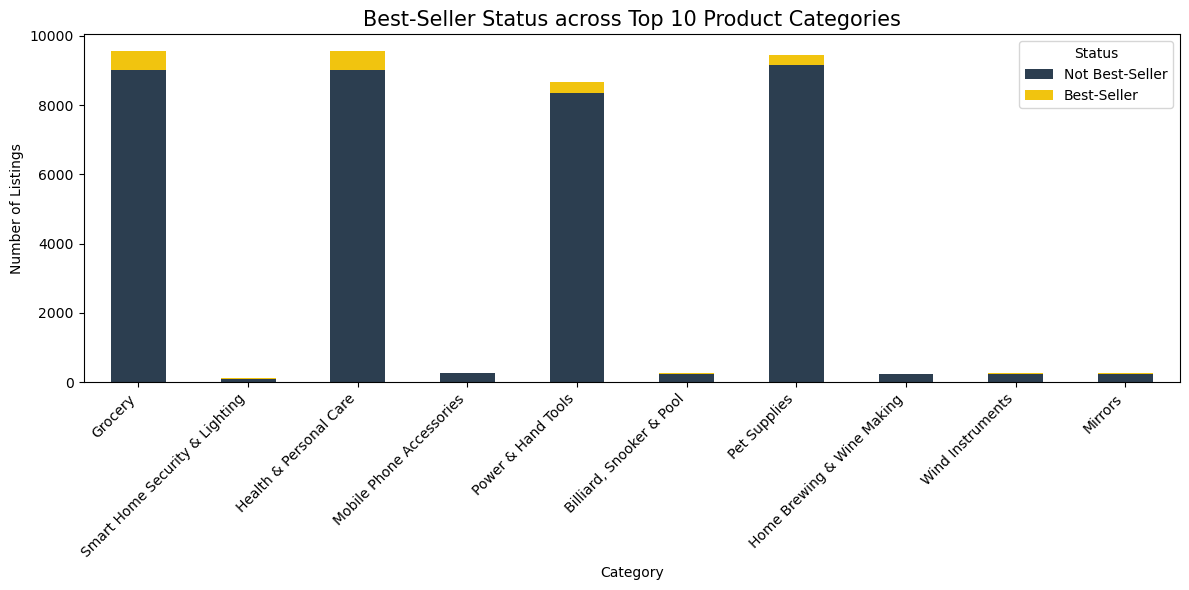

In [16]:
top_10_cats = best_seller_analysis.head(10).index
ct_subset = crosstab_cat_isBest.loc[top_10_cats]


ax = ct_subset.plot(kind = 'bar', stacked=True, figsize=(12,6), color = ['#2c3e50', '#f1c40f'])

ax.set_title("Best-Seller Status across Top 10 Product Categories", fontsize = 15)
ax.set_xlabel("Category")
ax.set_ylabel("Number of Listings")
ax.legend(["Not Best-Seller", "Best-Seller"], title="Status")
plt.xticks(rotation=45, ha = 'right') #ha='right', horizontal alignment, to tell Python to align the end (the right side) of the text string to the tick mark on the chart.
plt.tight_layout()
plt.show() 

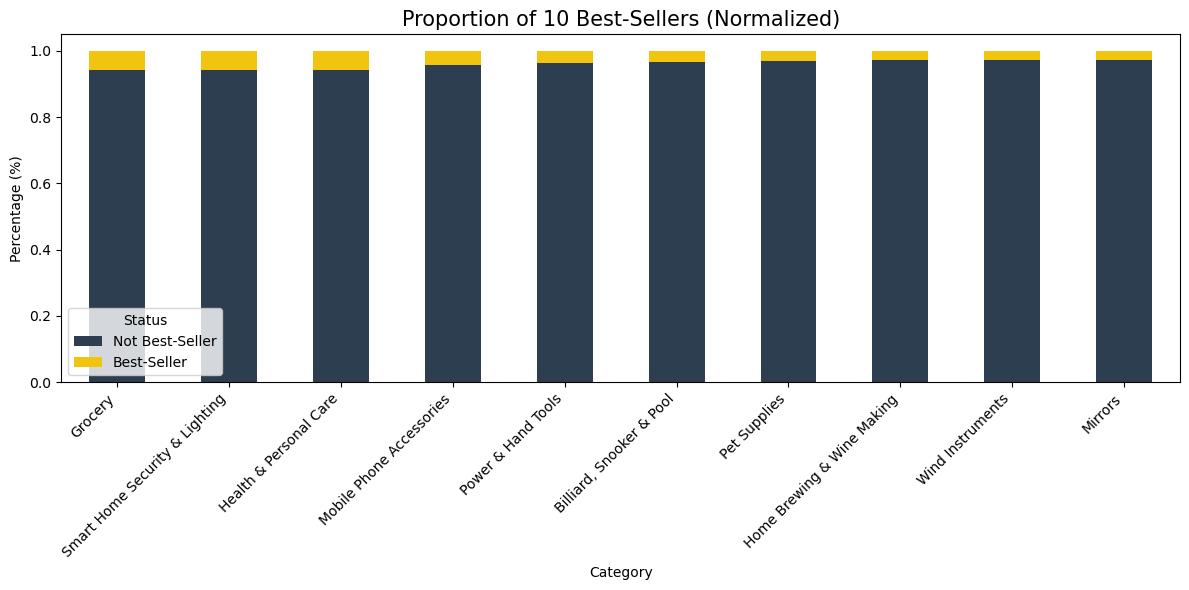

In [17]:
ct_normalized = ct_subset.div(ct_subset.sum(axis=1), axis=0) # Divide each row by its sum to turn counts into 0.0 - 1.0 percentages
#axis=0: Think Down (the Index/Rows). axis=1: Think Across (the Columns).

ax = ct_normalized.plot(kind = 'bar', stacked=True, figsize=(12,6), color = ['#2c3e50', '#f1c40f'])

ax.set_title("Proportion of 10 Best-Sellers (Normalized)", fontsize = 15)
ax.set_xlabel("Category")
ax.set_ylabel("Percentage (%)")
ax.legend(["Not Best-Seller", "Best-Seller"], title="Status")
plt.xticks(rotation=45, ha = 'right')
plt.tight_layout()
plt.show()

If we are looking at the normalized graph (where all bars are the same height), the yellow part looks like a thin "cap" on top of the blue.

    This visually confirms the Cramér's V of 0.12.
    If Category was a strong predictor of success (like a Cramér's V of 0.8), we would see some bars that are almost entirely yellow and others that are entirely blue.
    Instead, almost every bar is mostly blue, meaning that regardless of the category, it is still very hard to become a Best-Seller.

Visually, the stacked bar chart is dominated by the blue segments (Non-Best-Sellers), with the yellow 'Best-Seller' portions appearing as thin slices at the top. This illustrates the high barrier to entry for the Best-Seller badge across all categories. Even in high-performing niches like Grocery, the vast majority of products (over 94%) do not achieve Best-Seller status, highlighting that the badge remains an exclusive marker of top-tier performance rather than a common category trait.

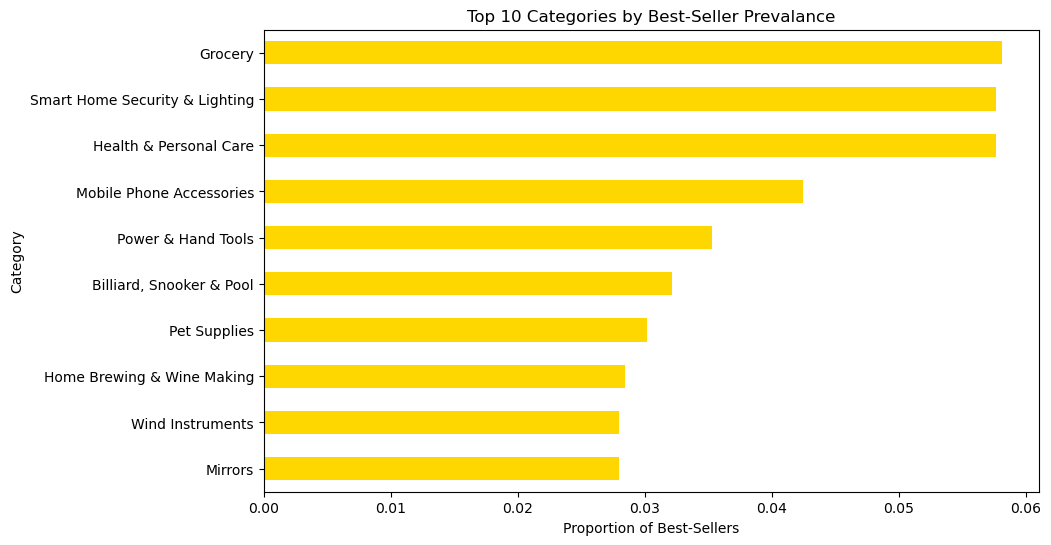

In [18]:
best_seller_analysis.head(10).plot(kind='barh', figsize=(10,6), color=['gold'])
plt.title('Top 10 Categories by Best-Seller Prevalance')
plt.xlabel('Proportion of Best-Sellers')
plt.ylabel('Category')
plt.gca().invert_yaxis()
plt.show()

3. Visual Confirmation

The normalized stacked bar chart confirms these stats. We see clear "efficiency leaders" like Grocery and Smart Home, which have a higher density of the yellow best-seller segments compared to the baseline. This visual discrepancy is exactly what the Chi-square test detected.

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [19]:
# Objective: Investigate how different product categories influence product prices.

# 1. Preliminary Step: Remove outliers in product prices.

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Original rows: {len(df)}")
print(f"Rows after removing outliers: {len(df_clean)}")

Original rows: 2443651
Rows after removing outliers: 2115963


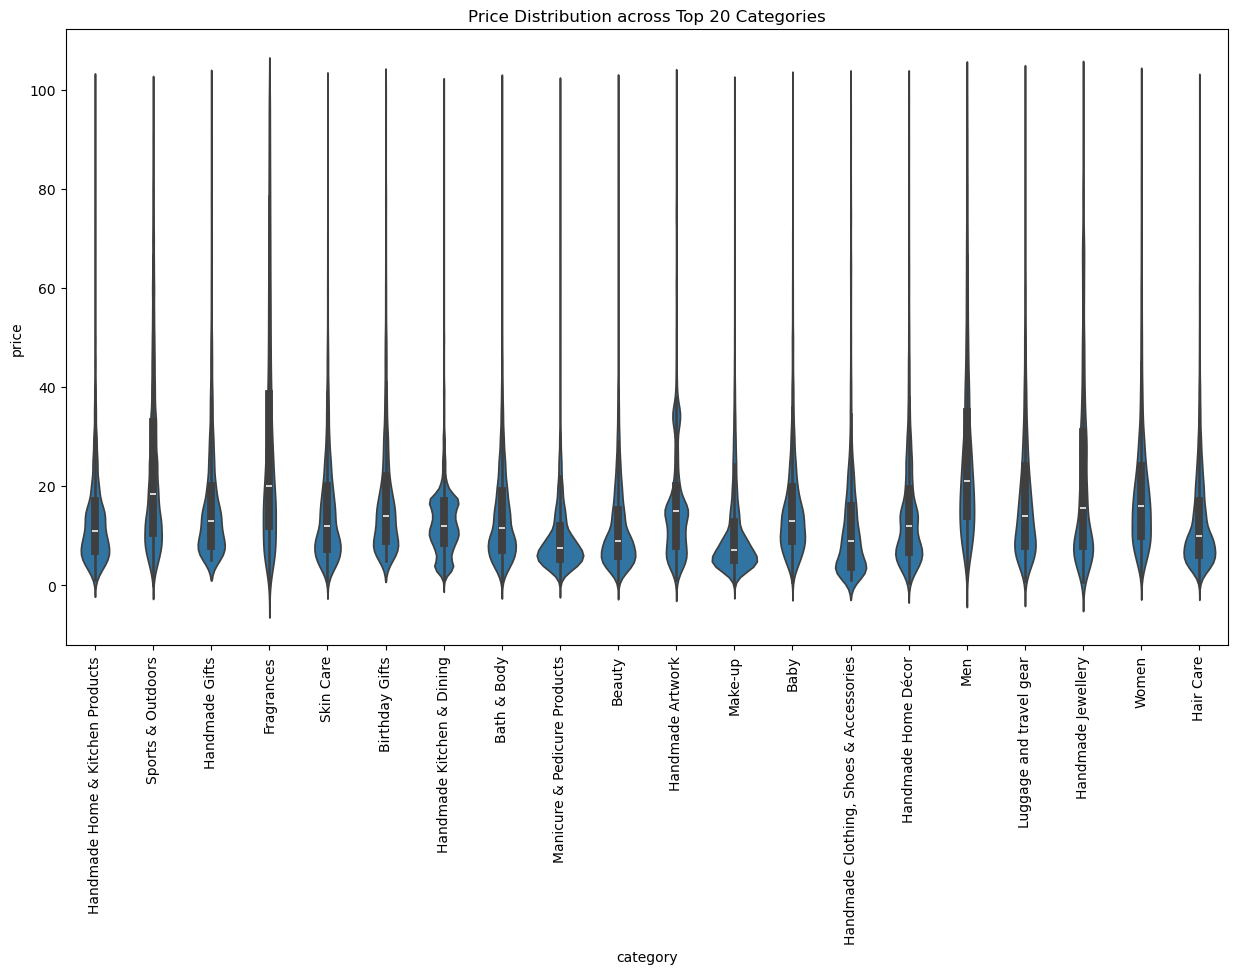

Category with highest median price: Desktop PCs (£74.00)


In [20]:
# 2. Violin Plots (Top 20 Categories)

top_20_cats = df_clean['category'].value_counts().head(20).index
df_top20 = df_clean[df_clean['category'].isin(top_20_cats)]

plt.figure(figsize=(15,8))
sns.violinplot(x='category', y='price', data = df_top20)
plt.xticks(rotation=90)
plt.title("Price Distribution across Top 20 Categories")
plt.show()

median_prices = df_clean.groupby('category')['price'].median().sort_values(ascending=False)
print(f"Category with highest median price: {median_prices.index[0]} (£{median_prices.iloc[0]:.2f})")

1. Violin Plot (Price Distribution - Top 20)

Looking at the violin plot, most categories show a "Fat Bottom" (near £0–£20).

    Observation: The "bulbs" are concentrated at the lower end of the Y-axis. This confirms that for the most common categories on Amazon UK, the vast majority of products are budget-friendly.

    The "Neck": The thin lines stretching upward show that even in common categories, there are "Premium" versions of items, but they are much rarer than the budget versions.

- Median Leader: Desktop PCs (£74.00). The median is the "middle" price, suggesting that half of all Desktop PCs are priced above £74.00. This is significantly higher than the overall dataset median of ~£19.

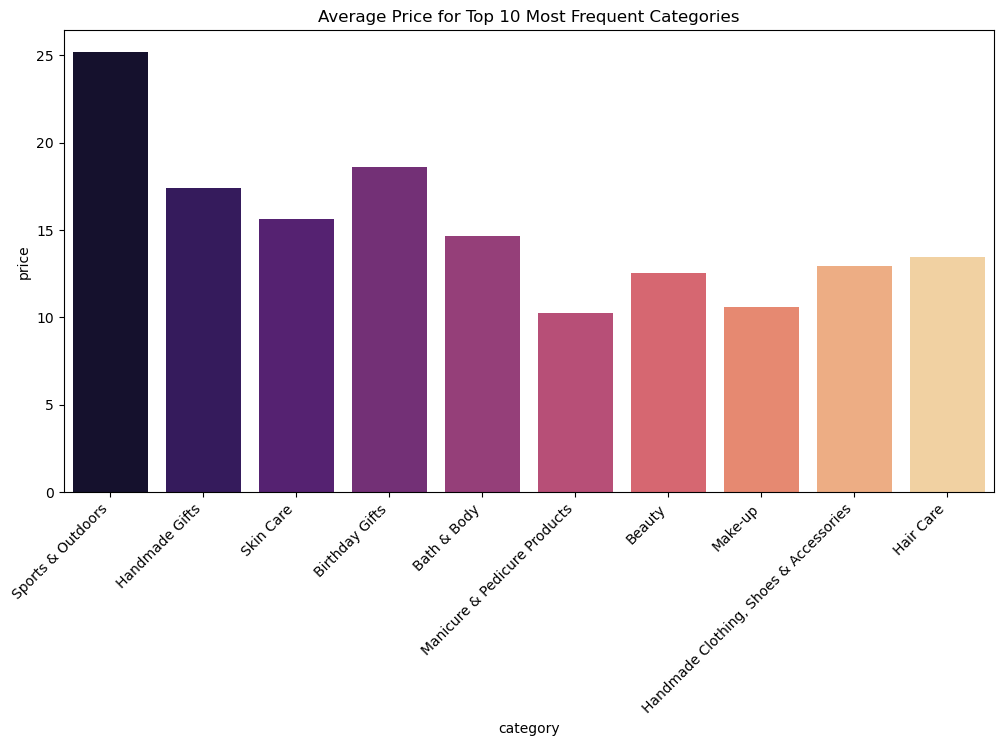

Category with highest average price: Motherboards (£68.77)


In [21]:
top_10_cats = df_clean['category'].value_counts().head(10).index
df_top10 = df_clean[df_clean['category'].isin(top_10_cats)]
                    
plt.figure(figsize=(12,6))
sns.barplot(x='category', y='price', data=df_top10, estimator='mean', errorbar = None, palette='magma', hue='category')
plt.xticks(rotation = 45, ha='right')
plt.title("Average Price for Top 10 Most Frequent Categories")
plt.show()

avg_prices = df_clean.groupby('category')['price'].mean().sort_index().sort_values(ascending=False)
print(f"Category with highest average price: {avg_prices.index[0]} (£{avg_prices.iloc[0]:.2f})")

2. Bar Chart (Average Price - Top 10)

This chart shows the "Price Ceiling" for the most frequent items.

    Observation: We can see which of the "Big Players" is the most expensive on average. Even though Sports & Outdoors has the most listings, a category like "Sports & Outdoors" actually commands more money per item on average. This helps a business decide where the "higher ticket" volume is.

- Average Leader: Motherboards (£68.77). Motherboards have the highest mean price, indicating they are consistently expensive components without as much "budget" variation as other categories.

- Business Insight: If Amazon UK wants to increase its Average Order Value (AOV), focusing on PC hardware is more effective than focusing on high-volume sports accessories.

C:\Users\Jawad\AppData\Local\Temp\ipykernel_24232\1738952950.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='stars', data=df_ratings_top10, palette='Set3')


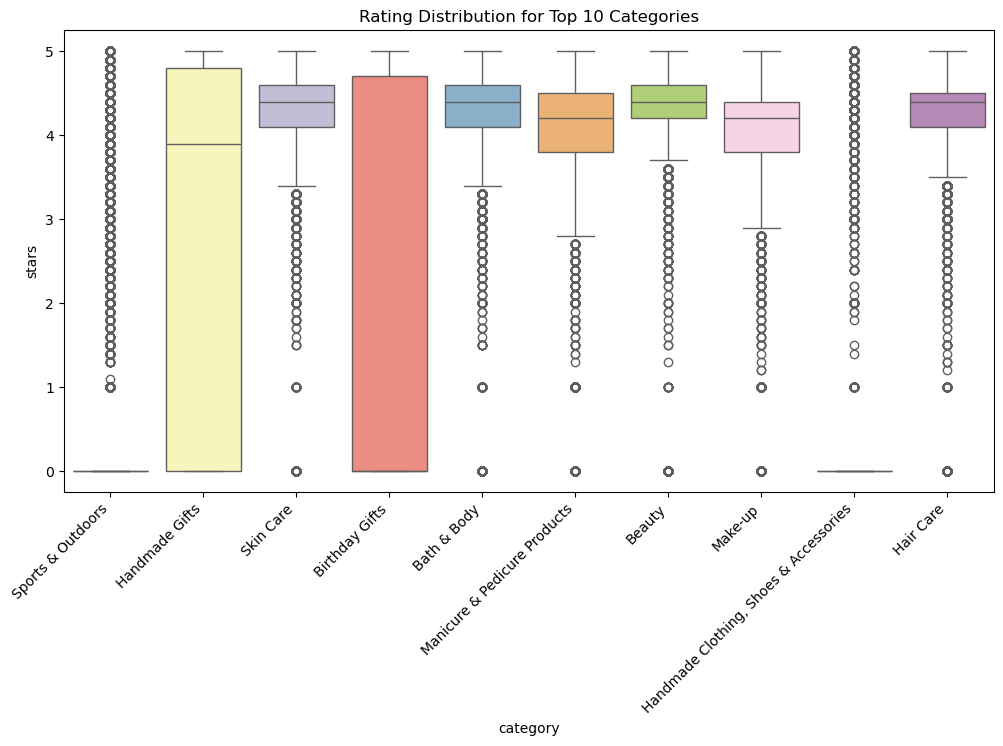

Category with highest median rating: Computer Memory (4.7 stars)


In [22]:
df_ratings_top10 = df_clean[df_clean['category'].isin(top_10_cats)]

plt.figure(figsize=(12,6))
sns.boxplot(x='category', y='stars', data=df_ratings_top10, palette='Set3')
plt.xticks(rotation=45, ha='right')
plt.title('Rating Distribution for Top 10 Categories')
plt.show()

median_ratings = df_clean.groupby('category')['stars'].median().sort_values(ascending=False)
print(f'Category with highest median rating: {median_ratings.index[0]} ({median_ratings.iloc[0]} stars)')

3. Box Plots (Rating Consistency - Top 10)

Since the Box Plot likely includes those 0-star "Unrated" products found in Part 3 of the univariate lab, we are seeing very long boxes or boxes that sit very low.

    Observation: The "Whiskers" (the lines stretching down) are very long. This visually confirms the high dispersion we calculated. It shows that in these top categories, customer experience is "all over the place", ranging from unrated (0) to perfect (5).

    The Median Line: The horizontal line inside each box tells us where the 50th percentile sits. If that line is low, it’s because of the 50.2% unrated products dragging it down.

- Business Insight: This is an incredible score. Computer Memory (RAM) is a technical product where performance is easily measured. A 4.7-star median suggests that sellers in this niche are highly reliable and that the products almost always meet customer technical expectations.


Our visualizations focus on the Top 10/20 categories by volume (e.g., Sports & Outdoors), which are characterized by low median prices and high rating volatility due to a large number of unrated listings.

However, when we look at the entire dataset without filtering for volume, we discover a 'Premium Niche' in Tech. Categories like Desktop PCs and Motherboards command significantly higher prices, and Computer Memory achieves the highest customer satisfaction (4.7 stars). While these tech categories don't have the sheer quantity of listings seen in the Top 10, they represent the highest quality and highest value segments of the Amazon UK marketplace.

While Sports & Outdoors represents the vast majority of Amazon UK listings, a bivariate analysis of price and ratings reveals that Computing Components are the true value drivers. Desktop PCs and Motherboards command the highest median and average prices, respectively, even after controlling for outliers.


# Part 3: Investigating the Interplay Between Product Prices and Ratings

In [23]:
# Objective: Analyze how product ratings (stars) correlate with product prices.

correlation = round(df_clean['price'].corr(df_clean['stars'], method = 'pearson'), 4)
print(f"Pearson correlation between Price and Stars: {correlation:.4f}")

Pearson correlation between Price and Stars: -0.0777


Is there a significant correlation between product price and its rating?

    "No. The Pearson correlation coefficient of -0.0777 indicates a negligible relationship. Statistically, knowing the price of a product on Amazon UK gives zero predictive power over how well-rated that product will be."

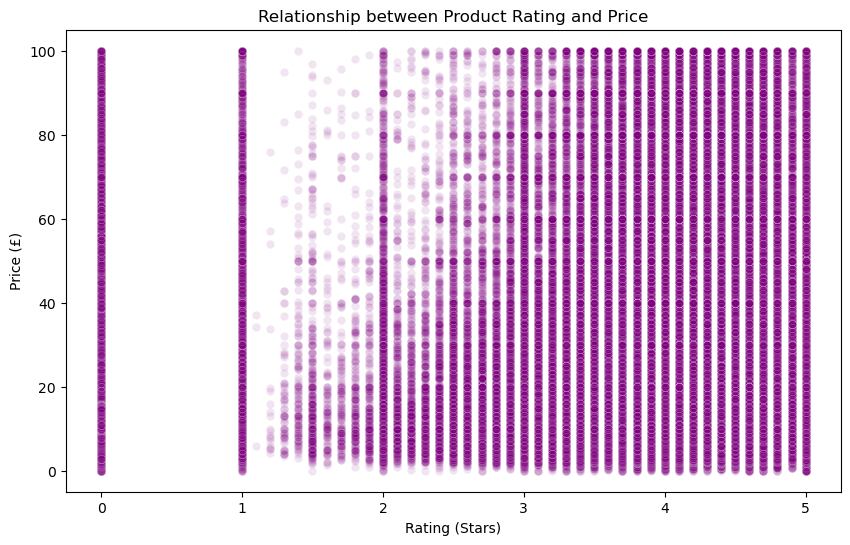

In [24]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_clean, x='stars', y='price', alpha=0.1, color='purple') # Since we have thousands of points, a standard scatter plot can look like a "blob." We use alpha to see the density.
plt.title("Relationship between Product Rating and Price")
plt.xlabel("Rating (Stars)")
plt.ylabel("Price (£)")
plt.show()

The scatter plot displays a 'random cloud' pattern with distinct vertical banding due to the discrete nature of star ratings. This is a visual proof of the -0.07 correlation. There is no visible trend line (slope), confirming that high-rated products are distributed evenly across the entire price spectrum, from budget items to premium goods.

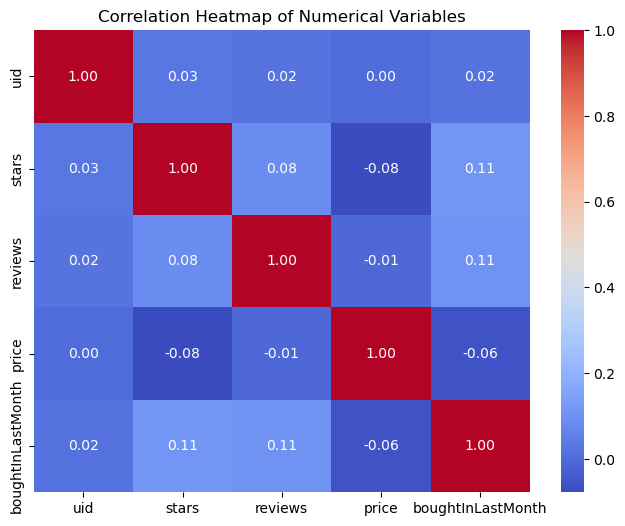

In [25]:
plt.figure(figsize=(8,6))
sns.heatmap(df_clean.select_dtypes(include=['number']).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

The cell for price vs stars shows that same -0.08 (rounded). The price/stars cell is colored dark blue indicating independence.

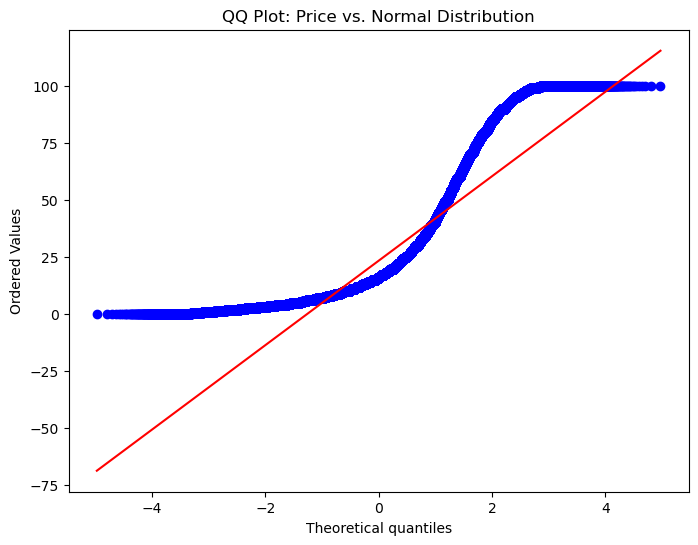

In [26]:
import scipy.stats as stats

plt.figure(figsize=(8,6))
stats.probplot(df_clean['price'], dist='norm', plot=plt)
plt.title("QQ Plot: Price vs. Normal Distribution")
plt.show()

In [27]:
bonus_corr = df['price'].corr(df['stars'])
print(f"Correlation (With Outliers): {bonus_corr:.4f}")
print(f"Correlation (Without Outliers): {correlation:.4f}")

Correlation (With Outliers): -0.1249
Correlation (Without Outliers): -0.0777


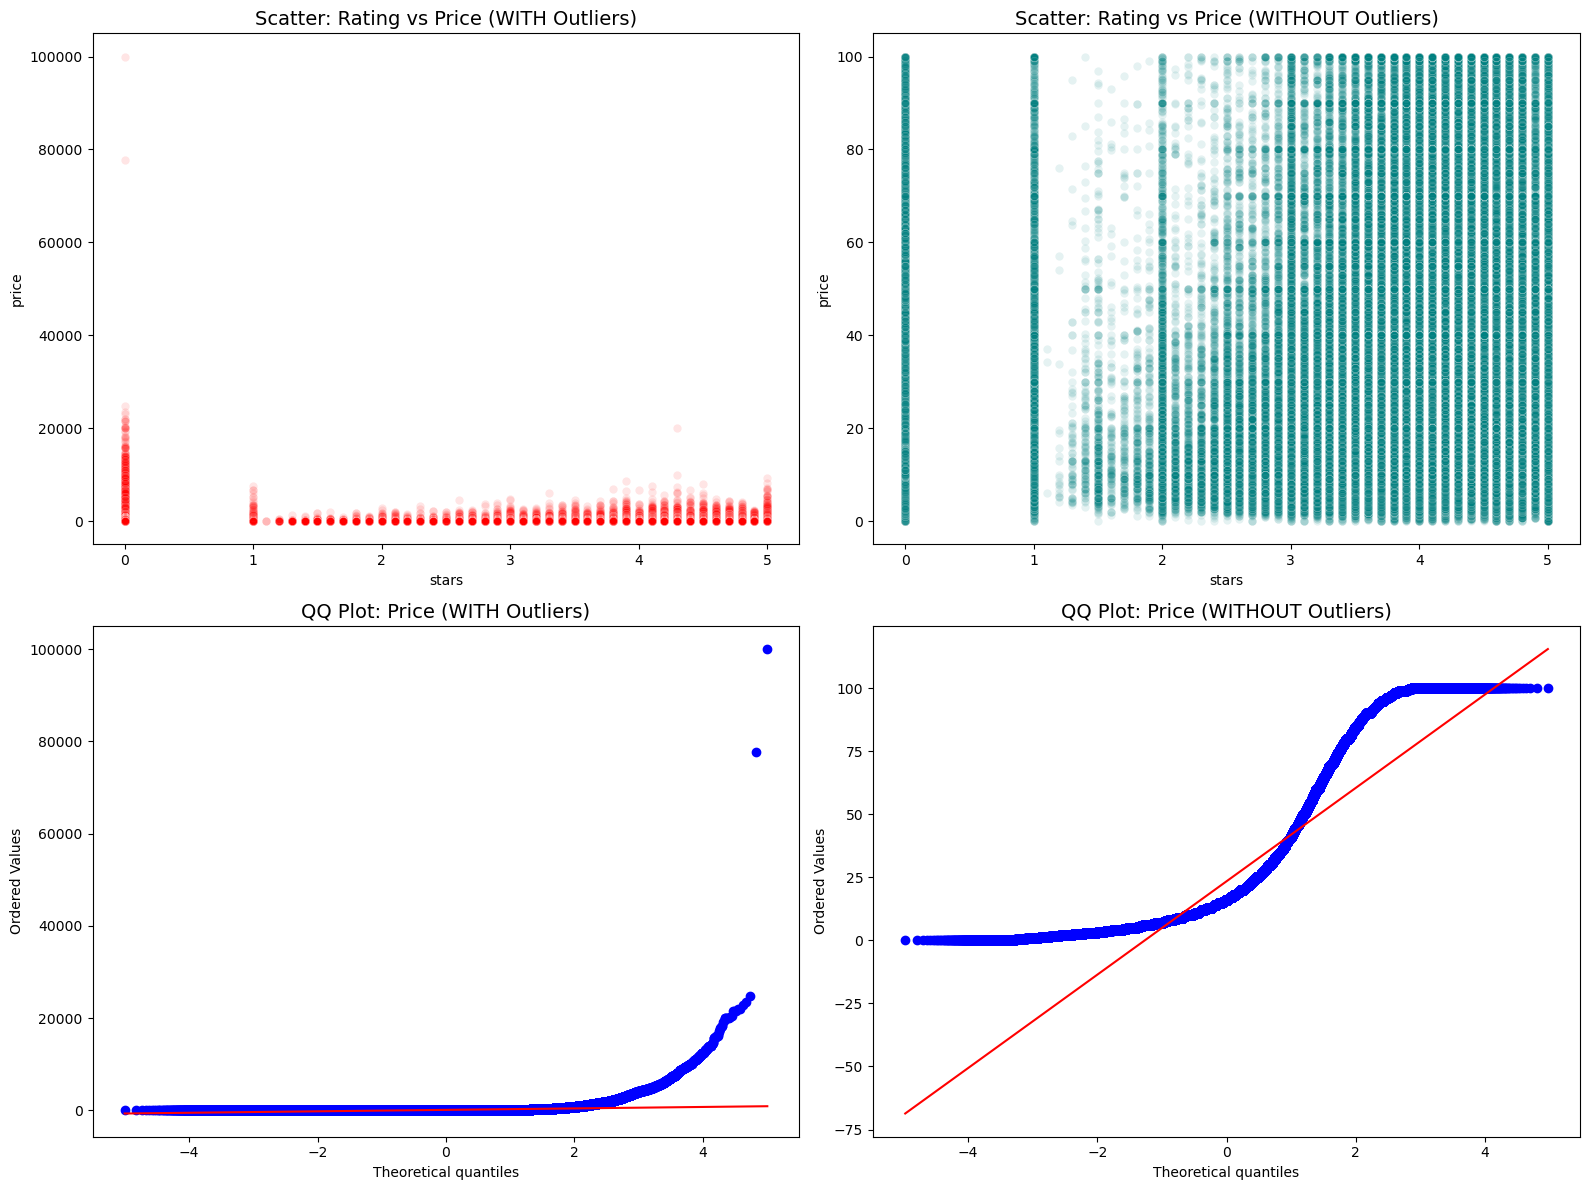

In [28]:
# 1. Define the Dataframes
# df = original data
# df_clean = data without price outliers (calculated earlier)

# Create a large plotting area (2 rows, 2 columns)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- ROW 1: SCATTER PLOTS (Rating vs Price) ---
# Left: With Outliers
sns.scatterplot(data=df, x='stars', y='price', alpha=0.1, color='red', ax=axes[0, 0])
axes[0, 0].set_title("Scatter: Rating vs Price (WITH Outliers)", fontsize=14)

# Right: Without Outliers
sns.scatterplot(data=df_clean, x='stars', y='price', alpha=0.1, color='teal', ax=axes[0, 1])
axes[0, 1].set_title("Scatter: Rating vs Price (WITHOUT Outliers)", fontsize=14)

# --- ROW 2: QQ PLOTS (Price Normality) ---
# Left: With Outliers
stats.probplot(df['price'], dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("QQ Plot: Price (WITH Outliers)", fontsize=14)

# Right: Without Outliers
stats.probplot(df_clean['price'], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("QQ Plot: Price (WITHOUT Outliers)", fontsize=14)

plt.tight_layout()
plt.show()

- The Probability Plot shows that prices do not follow a normal distribution. The significant upward deviation from the theoretical red line at the higher quantiles indicates a strong right skew. This confirms that the marketplace is dominated by low-cost items, with a few high-priced outliers stretching the distribution.

- The data shows that price and satisfaction are independent, and the market is heavily skewed toward affordable goods.

### Bonus Analysis: The Impact of Price Outliers

Retaining outliers in this analysis serves as a powerful case study for why Data Cleaning is the most critical step in the EDA process. When expensive products (e.g., £2,000 industrial equipment or £5,000 professional cameras) remain in the dataset, they disproportionately influence the statistical outcomes.
1. The "Mean" Trap (Bar Charts)

    Observations: With outliers, average prices for certain categories double or even triple. For example, if a category contains 100 products at £10 and a single outlier at £5,000, the mean surges from £10 to nearly £60.

    Insight: The Mean becomes a statistical distorter, failing to represent the spending habits of a typical customer. This highlights why Median is the preferred measure of central tendency for skewed financial data like Amazon prices.

2. Visual Distortion (Violin & Box Plots)

    Observations: Including outliers forces the Y-axis to scale from £0 to £5,000+.

    The Result: Since 99% of inventory is priced under £100, the primary distribution is crushed into a thin, unreadable line at the bottom of the chart. The characteristic bulbs of violin plots and the bodies of box plots vanish.

    Insight: Outliers monopolize the visual real estate. Removing them acts as a zoom lens, allowing us to analyze the 99% of products that drive daily transaction volume and business growth.

3. Impact on Correlation (Price vs. Rating)

    Metrics: Correlation without outliers: -0.077 | Correlation with outliers: -0.12.

    Analysis: The shift from -0.07 to -0.12 reveals that ultra-expensive products are more likely to receive lower ratings than the marketplace average.

    The Expectation Gap: In e-commerce, extreme price points often lead to hyper-critical customer expectations. A buyer may be delighted with a £10 yoga mat (4.5 stars), but a buyer of a £2,000 treadmill may leave a 1-star review for a minor mechanical flaw. These high-price/low-rating points pull the correlation line downward, artificially inflating the negative relationship.

4. The QQ Plot "Explosion"

    Observations: In the unfiltered QQ Plot, the data points do not merely curve; they shoot vertically off the theoretical normal line.

    Insight: This phenomenon represents Extreme Kurtosis and a Heavy-Tailed distribution. It signals to the business that the marketplace is not just skewed, but contains rare, high-impact values that can significantly bias standard predictive models.

Final Integrated Analysis: Amazon UK Marketplace
1. The Paradox of Consistency

    Univariate Finding: In the univariate lab, the product ratings were extremely polarized, either a product was unrated (0.0) or it was highly successful (4.5).

    Bivariate Finding: When we looked at Category vs. Best-Seller, we discovered why. The Best-Seller badge is an exclusive club. Most categories are dominated by unrated or average products, but categories like Grocery have a significantly higher "success density."

    Integrated Insight: Success on Amazon UK isn't evenly distributed. Some categories are naturally more "hit-driven," where consumer focus is concentrated on a small group of high-rated, high-performing items.

2. The Pricing Illusion

    Univariate Finding: The price distribution was heavily right-skewed, showing that Amazon is a "budget-first" platform with most items priced under £20.

    Bivariate Finding: By crossing Price with Stars, we found a correlation of nearly zero (-0.07).

    Integrated Insight: Price and Quality are decoupled in this marketplace. A higher price does not guarantee a better rating. In fact, our bonus analysis suggests that as prices reach extreme "outlier" levels, the correlation becomes more negative, likely due to an Expectation Gap where premium buyers become harder to please.

3. Volume vs. Value

    Univariate Finding: Sports & Outdoors is the undisputed king of volume, holding the most listings.

    Bivariate Finding: When looking at Price and Ratings by Category, "Tech" niches like Motherboards and Computer Memory emerged as the true value leaders, commanding higher average prices and the highest consumer trust (4.7 median rating).

    Integrated Insight: A business should not confuse "popular" with "premium." While Sports & Outdoors offers the most opportunities for entry, the Computing categories offer the highest potential for premium pricing and reliable customer satisfaction.

Conclusion:

The jump to Bivariate analysis proved that Data Cleaning (IQR method) was not just a technical chore, but a necessity for truth. Without removing outliers, the "average" Amazon experience was hidden behind the shadow of a few expensive industrial products.

Final Strategic Recommendation:
To succeed in the Amazon UK marketplace, a seller should focus on Category Selection over Price Hiking. Since price does not drive ratings, a seller's best strategy is to enter a high-density category like Grocery or a high-trust category like Computer Memory, rather than assuming a higher price tag will imply higher quality to the consumer.